# Module 04 — Diagnosing Training Loss

This notebook distinguishes difficult batches from damaged models, measures actual optimizer updates, and explores finite and non-finite training behavior.

## 1. Learning-rate instability on a quadratic loss

All runs start at `w = 0`; only the learning rate changes.

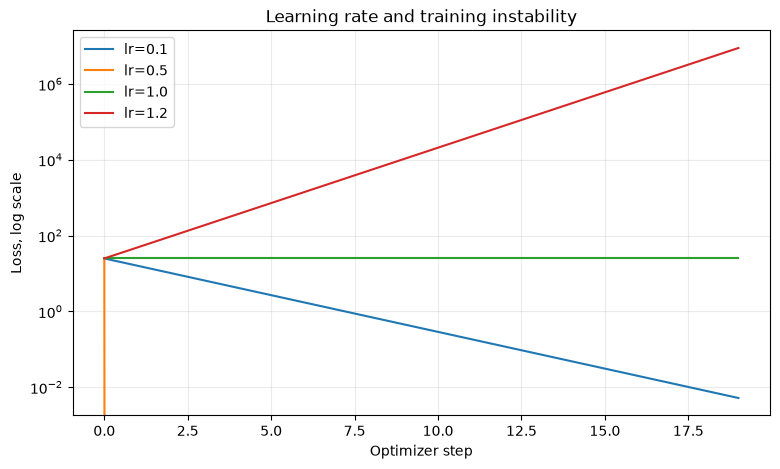

In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn


def train_toy(lr, steps=20):
    torch.manual_seed(42)
    weight = nn.Parameter(torch.tensor(0.0))
    optimizer = torch.optim.SGD([weight], lr=lr)
    history = {"loss": [], "gradient": [], "weight": []}

    for _ in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = (weight - 5.0) ** 2
        loss.backward()
        history["loss"].append(loss.item())
        history["gradient"].append(weight.grad.item())
        optimizer.step()
        history["weight"].append(weight.item())

    return history


learning_rates = (0.1, 0.5, 1.0, 1.2)
results = {lr: train_toy(lr) for lr in learning_rates}

plt.figure(figsize=(9, 5))
for lr, history in results.items():
    plt.plot(history["loss"], label=f"lr={lr}")

plt.yscale("log")
plt.xlabel("Optimizer step")
plt.ylabel("Loss, log scale")
plt.title("Learning rate and training instability")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 2. Compare gradient and weight behavior

An unstable run can be badly diverging while all values are still finite.

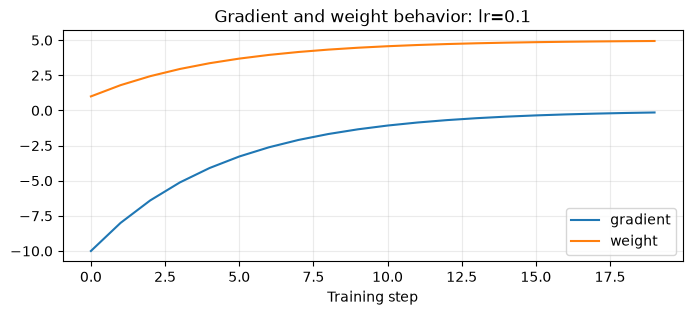

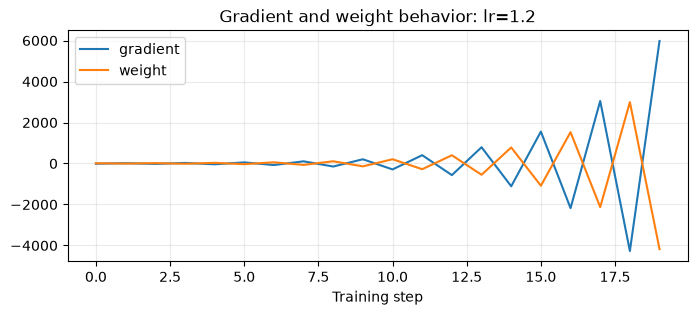

In [2]:
for lr in (0.1, 1.2):
    history = results[lr]
    plt.figure(figsize=(8, 3))
    plt.plot(history["gradient"], label="gradient")
    plt.plot(history["weight"], label="weight")
    plt.title(f"Gradient and weight behavior: lr={lr}")
    plt.xlabel("Training step")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

## 3. Build a reusable training-step debugger

The debugger checks finiteness and records loss, gradient norm, update norm, weight norm, and learning rate.

In [3]:
import torch.nn.functional as F


def global_norm(tensors):
    norms = [
        tensor.detach().float().norm(2)
        for tensor in tensors
        if tensor is not None
    ]
    if not norms:
        return 0.0
    return torch.linalg.vector_norm(torch.stack(norms), ord=2).item()


def debug_train_step(model, optimizer, x, y):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    before = {
        name: parameter.detach().clone()
        for name, parameter in model.named_parameters()
    }

    logits = model(x)
    if not torch.isfinite(logits).all():
        raise FloatingPointError("Non-finite logits")

    loss = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        y.reshape(-1),
    )
    if not torch.isfinite(loss):
        raise FloatingPointError("Non-finite loss")

    loss.backward()
    gradients = [
        parameter.grad
        for parameter in model.parameters()
        if parameter.grad is not None
    ]
    if any(not torch.isfinite(gradient).all() for gradient in gradients):
        raise FloatingPointError("Non-finite gradients")

    grad_norm = global_norm(gradients)
    optimizer.step()

    parameters = list(model.parameters())
    if any(not torch.isfinite(parameter).all() for parameter in parameters):
        raise FloatingPointError("Non-finite parameters")

    update_norm = global_norm(
        parameter.detach() - before[name]
        for name, parameter in model.named_parameters()
    )
    weight_norm = global_norm(parameter for parameter in parameters)

    return {
        "loss": loss.item(),
        "grad_norm": grad_norm,
        "update_norm": update_norm,
        "weight_norm": weight_norm,
        "lr": optimizer.param_groups[0]["lr"],
    }

In [4]:
debug_model = nn.Sequential(
    nn.Embedding(32, 16),
    nn.Flatten(start_dim=1),
    nn.Linear(16 * 8, 32),
)
debug_optimizer = torch.optim.AdamW(debug_model.parameters(), lr=1e-3)
debug_x = torch.randint(0, 32, (4, 8))
debug_y = torch.randint(0, 32, (4, 1)).squeeze(1)

# The model returns one vocabulary distribution per sequence here.
stats = debug_train_step(debug_model, debug_optimizer, debug_x, debug_y)
print(stats)

{'loss': 3.2149767875671387, 'grad_norm': 5.488697052001953, 'update_norm': 0.06693008542060852, 'weight_norm': 22.212299346923828, 'lr': 0.001}


## 4. Inspect non-finite arithmetic

Use small reproductions to understand where `Inf` and `NaN` come from.

In [5]:
x = torch.tensor([60000.0], dtype=torch.float16)
overflow = x * 2
invalid_from_inf = overflow / overflow
invalid_sqrt = torch.sqrt(torch.tensor([-1.0]))

print("Overflow:", overflow)
print("Invalid operation:", invalid_from_inf)
print("Invalid square root:", invalid_sqrt)
print("Finite checks:", [
    torch.isfinite(value).all().item()
    for value in (overflow, invalid_from_inf, invalid_sqrt)
])

Overflow: tensor([inf], dtype=torch.float16)
Invalid operation: tensor([nan], dtype=torch.float16)
Invalid square root: tensor([nan])
Finite checks: [False, False, False]


## Exercises

1. Compare current-batch loss with a fixed diagnostic batch during a toy run.
2. Log the update-to-weight ratio from the debugger.
3. Enable anomaly detection for one backward pass and compare runtime.
4. Add a forward hook to the model and deliberately introduce a non-finite activation.